,variable,missing_count,missing_percentage
9,CO,20701,4.919813
10,O3,13277,3.155421
8,NO2,12116,2.879497
7,SO2,9021,2.143937
5,pm25,8739,2.076916
6,PM10,6449,1.532674
15,wd,1822,0.433018
13,DEWP,403,0.095777
11,TEMP,398,0.094589
12,PRES,393,0.093401


,variable,q1,q3,lower_bound,upper_bound,outlier_count
2,SO2,3.0,19.0,-21.00,43.00,38275
4,CO,500.0,1500.0,-1000.00,3000.00,28054
10,WSPM,0.9,2.2,-1.05,4.15,23079
0,pm25,20.0,111.0,-116.50,247.50,19142
9,RAIN,0.0,0.0,0.00,0.00,16520
5,O3,10.0,82.0,-98.00,190.00,15978
1,PM10,36.0,144.0,-126.00,306.00,15004
3,NO2,24.0,72.0,-48.00,144.00,6760
6,TEMP,3.3,23.0,-26.25,52.55,0
8,DEWP,-9.1,15.0,-45.25,51.15,0


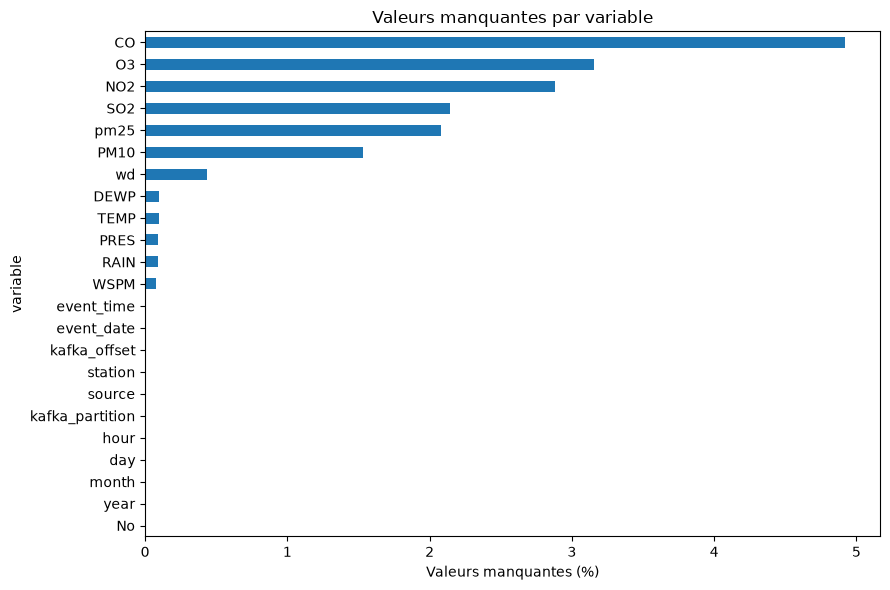

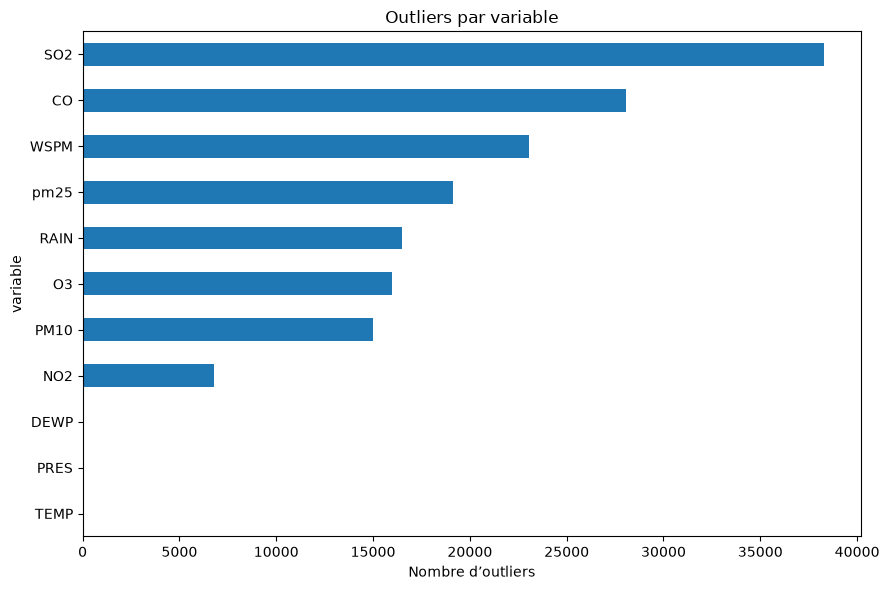

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

GOLD_DIR = Path(
    r"C:\Users\ADMIN\Desktop\AirWatch\analytics\outputs\aggregated_data\airwatch_gold"
)

def load_spark_csv(name):
    files = sorted((GOLD_DIR / name).glob("part-*.csv"))
    if not files:
        raise FileNotFoundError(f"Aucun CSV trouvé dans {GOLD_DIR / name}")
    return pd.concat([pd.read_csv(file) for file in files], ignore_index=True)

missing = load_spark_csv("missing_values")
outliers = load_spark_csv("outlier_analysis")

display(missing.sort_values("missing_percentage", ascending=False))
display(outliers.sort_values("outlier_count", ascending=False))

missing.sort_values("missing_percentage").plot.barh(
    x="variable", y="missing_percentage", legend=False, figsize=(9, 6)
)
plt.xlabel("Valeurs manquantes (%)")
plt.title("Valeurs manquantes par variable")
plt.tight_layout()
plt.show()

outliers.sort_values("outlier_count").plot.barh(
    x="variable", y="outlier_count", legend=False, figsize=(9, 6)
)
plt.xlabel("Nombre d’outliers")
plt.title("Outliers par variable")
plt.tight_layout()
plt.show()